# Observation windows: one vocabulary for every window the platform uses

This notebook resolves the **observation window vs performance window** confusion and
measures the real window sizes from the loaded DuckDB, not from memory.

- Vocabulary and timeline: cells 2-4.
- Measured windows (months on book, censoring, coverage heatmap, (t0, horizon) counts): cells 5-8.
- Leakage cross-check against `field_leakage_table` and `feature_catalogue_table`: cell 9.

Settings come from environment variables `WIN_DB`, `WIN_SAMPLE`, `WIN_THREADS`
(same pattern as `02_eda.ipynb`). The default is the 10% sample.


In [1]:
%matplotlib inline
import os
import sys
import time
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

T0 = time.time()

def find_repo_root():
    here = Path.cwd().resolve()
    for folder in [here] + list(here.parents):
        if (folder / 'residential_mortgage').is_dir():
            return folder
    raise RuntimeError('Cannot find the folder that holds residential_mortgage')

REPO = find_repo_root()
DB_PATH = Path(os.environ.get('WIN_DB', REPO / 'residential_mortgage' / '00_data' / 'processed' / 'mortgages.duckdb'))
USE_SAMPLE = os.environ.get('WIN_SAMPLE', '1') == '1'
THREADS = int(os.environ['WIN_THREADS']) if os.environ.get('WIN_THREADS') else None
SCOPE_LABEL = '10% sample run' if USE_SAMPLE else 'full data'

# windows.py sits at the portfolio root so 01, 02 and 03 can all import it.
sys.path.insert(0, str(REPO / 'residential_mortgage'))
import windows as W

con = duckdb.connect(str(DB_PATH), read_only=True)
if THREADS:
    con.execute(f'SET threads = {THREADS}')

print(f'Database: {DB_PATH.name}; scope: {SCOPE_LABEL}')
print(f'Windows config: {Path(W.__file__).name}')


Database: mortgages.duckdb; scope: 10% sample run
Windows config: windows.py


## The vocabulary, once and for all

The two names people confuse: the **observation (feature) window** looks backward from the
snapshot date t0 and ends at t0-1; the **performance (outcome) window** looks forward from
t0 and is where the label is measured. Anything filled inside the performance window that
ends up in a feature is target leakage.

The single source is `residential_mortgage/windows.py`. The table below is its
`WINDOW_VOCABULARY`.


In [2]:
vocab = pd.DataFrame(W.WINDOW_VOCABULARY)
display(vocab)


,window,direction,definition,value,source
0,Snapshot date (t0),point,The month a model freezes its features and sco...,Every December 2000-2025 (book_snapshot); mont...,"M2-12, M2-13"
1,Observation / feature window,backward,Months before t0 whose values become features....,lookback 6 months (and 12 for worst-12/payment...,feature catalogue; stage 7
2,Performance / outcome window,forward,Months after t0 over which the label is measur...,12 months (default); 24 for re-default,M2-9; stage 9
3,Sample coverage window,global,"The calendar span of the whole panel, independ...","2000Q1-2025Q4 (104 acquisition quarters), data...",loaded_quarters_table
4,Seasoning window,backward,Minimum months on book before a loan is eligib...,6 months (masked-balance months),M2 data facts
5,Maturity / censoring window,forward,How much of the performance window a loan has ...,measured per vintage in 05_observation_windows...,05_observation_windows.ipynb
6,Cure / probation window,forward,Clean months after default before a loan re-en...,3 months arrears default; 12 months restructuring,"M2-5 (178(5)(a), 178(5A))"
7,Projection horizon,forward,"Forward periods for roll-rate / PD projection,...","[6, 12, 24, 36] months",stage 3
8,Emergence lag,forward,Time from first missed payment to recognition ...,3 months behind (90-119 DPD),M2-3 (178(1)(b))


## The timeline

One picture of the vocabulary. The shaded bar left of t0 is the observation window; the
shaded bar right of t0 is the performance window. Seasoning sits before the first usable
observation; probation, emergence and projection all sit after t0.


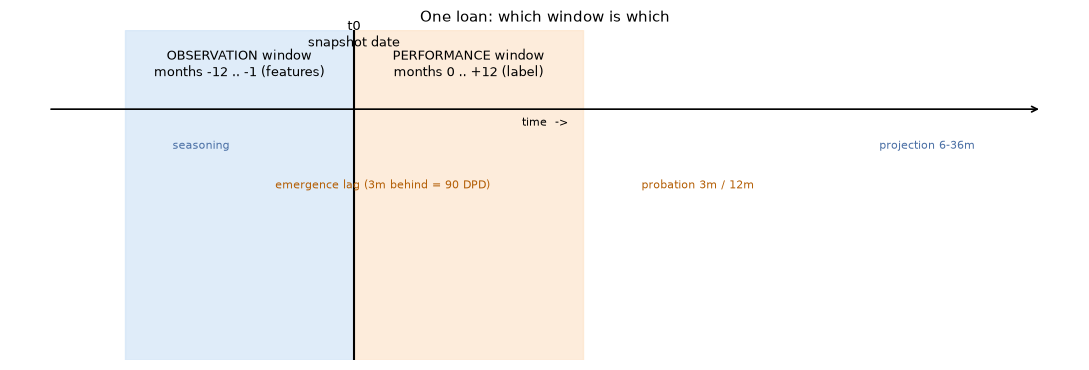

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.set_xlim(-18, 38)
ax.set_ylim(0, 10)
ax.axis('off')

# Observation (feature) window: backward from t0, ends at t0-1
ax.axvspan(-12, 0, color='#cfe3f7', alpha=0.65)
ax.text(-6, 8.6, 'OBSERVATION window\nmonths -12 .. -1 (features)', ha='center', fontsize=9)
# Performance (outcome) window: forward from t0
ax.axvspan(0, 12, color='#fde3c8', alpha=0.65)
ax.text(6, 8.6, 'PERFORMANCE window\nmonths 0 .. +12 (label)', ha='center', fontsize=9)
# t0
ax.axvline(0, color='black', lw=1.5)
ax.text(0, 9.5, 't0\nsnapshot date', ha='center', fontsize=9)
# time axis
ax.annotate('', xy=(36, 7.6), xytext=(-16, 7.6), arrowprops=dict(arrowstyle='->', lw=1.2))
ax.text(10, 7.1, 'time  ->', ha='center', fontsize=8)
# markers below the axis
ax.annotate('seasoning', xy=(-8, 6.4), ha='center', fontsize=8, color='#4a6fa5')
ax.annotate('emergence lag (3m behind = 90 DPD)', xy=(1.5, 5.2), ha='center', fontsize=8, color='#b45f06')
ax.annotate('probation 3m / 12m', xy=(18, 5.2), ha='center', fontsize=8, color='#b45f06')
ax.annotate('projection 6-36m', xy=(30, 6.4), ha='center', fontsize=8, color='#4a6fa5')
plt.title('One loan: which window is which', fontsize=11)
plt.tight_layout()
plt.show()


## Measured windows from the data

Everything below comes from `loan_monthly_view` (`loan_age` = months on book). The heavy
work is done in **one** per-loan aggregation, then the rest reads that small table in
Python, so this cell is the only full pass over the monthly rows.


In [4]:
t_scan = time.time()
sample_clause = ('WHERE loan_id IN (SELECT loan_id FROM sampled_loans_table)'
                 if USE_SAMPLE else '')
sql = f'''
SELECT
    loan_id,
    acquisition_quarter AS vintage,
    MIN(loan_age) AS first_mob,
    MAX(loan_age) AS last_mob,
    COUNT(*) AS n_months,
    BOOL_OR(exit_reason IS NOT NULL) AS exited
FROM loan_monthly_view
{sample_clause}
GROUP BY loan_id, acquisition_quarter
'''
per_loan = con.execute(sql).df()
print(f'per-loan summary: {len(per_loan):,} loans in {time.time() - t_scan:.0f}s')

mob_by_vintage = (
    per_loan.groupby('vintage')
    .agg(loans=('loan_id', 'size'),
         min_mob=('first_mob', 'min'),
         max_mob=('last_mob', 'max'),
         median_mob=('last_mob', 'median'))
    .reset_index()
)
display(mob_by_vintage)


per-loan summary: 5,759,759 loans in 397s


,vintage,loans,min_mob,max_mob,median_mob
0,2000Q1,24686,-1,315,27.0
1,2000Q2,27434,-1,317,19.0
2,2000Q3,33350,-1,314,17.0
3,2000Q4,36389,-1,319,20.0
4,2001Q1,47128,-1,320,22.0
...,...,...,...,...,...
99,2024Q4,25055,-1,26,13.0
100,2025Q1,19210,-1,18,10.0
101,2025Q2,24694,-1,18,7.0
102,2025Q3,26370,-1,19,4.0


## Censoring: how much of the performance window is realized

For a loan to be a complete case at observation month t0 over a horizon h, its history
must reach t0 + h. `last_mob` is the last month on book the loan reports (exit rows have
no `loan_age`), so `last_mob >= t0 + h` means the full outcome window was realized. Loans
with `last_mob < t0 + h` are censored at the data's edge or by exit.


In [5]:
def coverage(t0, h):
    eligible = int((per_loan['last_mob'] >= t0).sum())
    complete = int((per_loan['last_mob'] >= t0 + h).sum())
    censored = eligible - complete
    rate = complete / eligible if eligible else float('nan')
    return eligible, complete, censored, rate

rows = []
for t0 in [6, 12, 24, 36]:
    for h in [12, 24]:
        eligible, complete, censored, rate = coverage(t0, h)
        rows.append({'t0_mob': t0, 'horizon_months': h, 'eligible_loans': eligible,
                     'complete_loans': complete, 'censored_loans': censored,
                     'coverage_pct': round(100 * rate, 2) if rate == rate else None})
coverage_df = pd.DataFrame(rows)
display(coverage_df)


,t0_mob,horizon_months,eligible_loans,complete_loans,censored_loans,coverage_pct
0,6,12,5512850,4562565,950285,82.76
1,6,24,5512850,3759490,1753360,68.20
2,12,12,5058854,4128950,929904,81.62
3,12,24,5058854,3440057,1618797,68.00
4,24,12,4128950,3440057,688893,83.32
5,24,24,4128950,2818492,1310458,68.26
6,36,12,3440057,2818492,621565,81.93
7,36,24,3440057,2084685,1355372,60.60


## Vintage x months-on-book coverage heatmap

Each cell is the share of a vintage still observed at that month on book (its observation
survival). Early vintages reach high MOB; recent vintages fade early because the data ends
at December 2025.


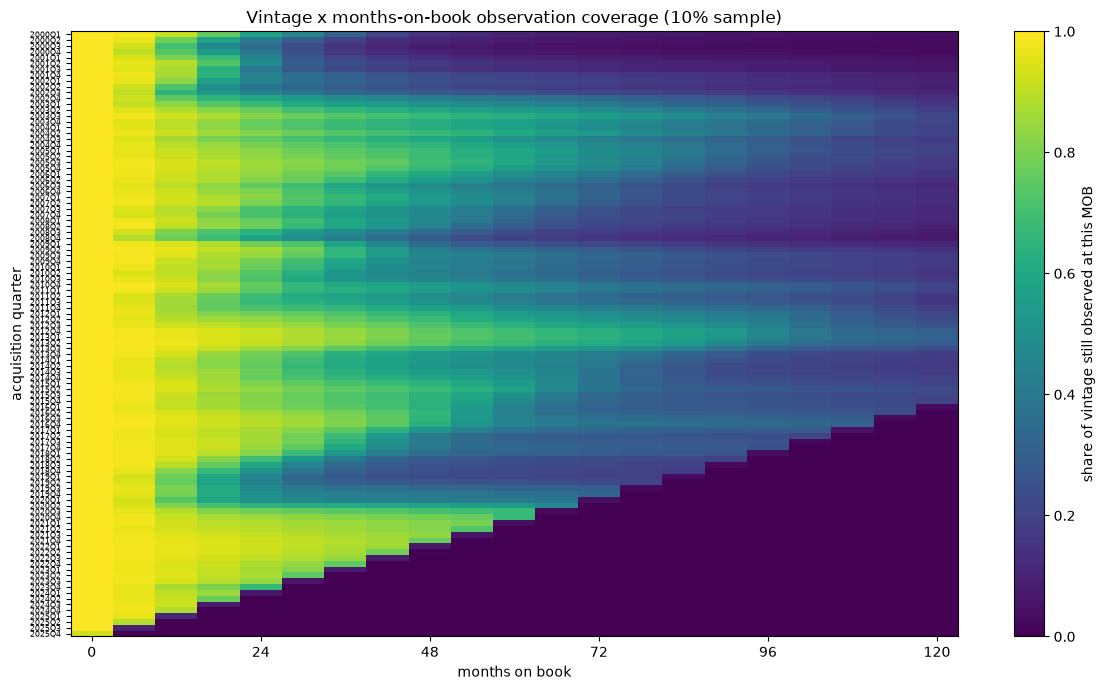

In [6]:
mob_grid = list(range(0, 121, 6))
vintages = sorted(per_loan['vintage'].unique())
matrix = np.full((len(vintages), len(mob_grid)), np.nan)
for i, v in enumerate(vintages):
    last = per_loan.loc[per_loan['vintage'] == v, 'last_mob'].to_numpy()
    total = len(last)
    if total:
        matrix[i] = [(last >= m).sum() / total for m in mob_grid]

fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(matrix, aspect='auto', cmap='viridis', vmin=0, vmax=1)
ax.set_xticks(range(0, len(mob_grid), 4))
ax.set_xticklabels(mob_grid[::4])
ax.set_yticks(range(len(vintages)))
ax.set_yticklabels(vintages, fontsize=6)
ax.set_xlabel('months on book')
ax.set_ylabel('acquisition quarter')
plt.colorbar(im, label='share of vintage still observed at this MOB')
plt.title('Vintage x months-on-book observation coverage (10% sample)')
plt.tight_layout()
plt.show()


## Leakage cross-check

Each field is placed in a window from its `field_class` in `field_leakage_table` and
`feature_catalogue_table`. The rule: `quarantined` fields sit inside the performance
window and may only build targets; `monthly_lag_1` fields sit inside the observation
window and are used at t0-1 or earlier. This is the same rule the feature catalogue
enforces, shown here in window terms.


In [7]:
leakage = con.execute(
    'SELECT field_name, source_object, field_class, lag_rule, usable_as_feature, reason '
    'FROM field_leakage_table ORDER BY field_name').df()
catalogue = con.execute(
    'SELECT field_name, source_object, treatment_note FROM feature_catalogue_table').df()

def window_of(cls):
    return {
        'key': 'outside windows (join/order)',
        'origination': 'before t0 (fixed at origination)',
        'monthly_lag_1': 'observation window, ends t0-1',
        'quarantined': 'performance window (targets only)',
    }[cls]

merged = leakage.merge(catalogue, on=['field_name', 'source_object'], how='left')
merged['window'] = merged['field_class'].map(window_of)
display(merged[['field_name', 'source_object', 'field_class', 'lag_rule', 'usable_as_feature', 'window']])
print('Fields inside the performance window (quarantined):',
      int((merged['field_class'] == 'quarantined').sum()))
print('Fields in the observation window (monthly_lag_1):',
      int((merged['field_class'] == 'monthly_lag_1').sum()))
print(f'Total time: {time.time() - T0:.0f}s')


,field_name,source_object,field_class,lag_rule,usable_as_feature,window
0,acquisition_quarter,loans_table,key,join only,False,outside windows (join/order)
1,acquisition_quarter,loan_monthly_view,key,join only,False,outside windows (join/order)
2,alt_delinquency_resolution,loan_monthly_view,monthly_lag_1,t-1,True,"observation window, ends t0-1"
3,alt_delinquency_resolution_count,loan_monthly_view,monthly_lag_1,t-1,True,"observation window, ends t0-1"
4,amortization_type,loans_table,origination,none,True,before t0 (fixed at origination)
...,...,...,...,...,...,...
73,total_principal,loan_monthly_view,monthly_lag_1,t-1,True,"observation window, ends t0-1"
74,upb_at_removal,loan_monthly_view,quarantined,never,False,performance window (targets only)
75,zero_balance_code,loan_monthly_view,quarantined,never,False,performance window (targets only)
76,zero_balance_date,loan_monthly_view,quarantined,never,False,performance window (targets only)


Fields inside the performance window (quarantined): 19
Fields in the observation window (monthly_lag_1): 21
Total time: 426s


## Where each window constant lives

- Analytical windows and horizons: `residential_mortgage/windows.py` (this notebook's source).
- `DPD_DEFAULT_MONTHS`, `PROBATION_ARREARS_MONTHS`, `PROBATION_RESTRUCTURING_MONTHS` also
  live in `windows.py` for now; they move to `regulatory_parameters.py` at Module 2 sign-off.
- Consumers: `02_portfolio_analytics/06_default_rate_history.py` (snapshot/out-of-time gate)
  and the Module 3 scorecard/PD builders import `windows` directly.
